<a href="https://colab.research.google.com/github/jahnavireddy-27/Exploratory-Data-Analysis-on-Customer-Data-set/blob/master/EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Case study on User / Customer Retention dataset. Perform EDA with Feature Selection and make your assessments. BY: Jahnavi GongalReddy AP21110011335

In [ ]:
import numpy as np
import pandas as pd
df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
pd.options.display.float_format = '{:,.2f}'.format
def summary(df):
    print(f'data shape: {df.shape}')
    summ = pd.DataFrame(df.dtypes, columns=['data type'])
    summ['#missing'] = df.isnull().sum().values
    summ['%missing'] = df.isnull().sum().values / len(df) * 100
    summ['#duplicated'] = df.duplicated()
    summ['%duplicated'] = df.duplicated()/ len(df) * 100
    summ['#unique'] = df.nunique().values
    desc = pd.DataFrame(df.describe(include='all').transpose())
    summ['min'] = desc['min'].values
    summ['max'] = desc['max'].values
    summ['average'] = desc['mean'].values
    summ['standard_deviation'] = desc['std'].values
    summ['first value'] = df.loc[0].values
    summ['second value'] = df.loc[1].values
    summ['third value'] = df.loc[2].values

    return summ

In [ ]:
summary(df).style.background_gradient(cmap='YlOrBr')

data shape: (7043, 21)


/usr/local/lib/python3.10/dist-packages/pandas/io/formats/style.py:3931: RuntimeWarning: All-NaN slice encountered
  smin = np.nanmin(gmap) if vmin is None else vmin
/usr/local/lib/python3.10/dist-packages/pandas/io/formats/style.py:3932: RuntimeWarning: All-NaN slice encountered
  smax = np.nanmax(gmap) if vmax is None else vmax


,data type,#missing,%missing,#duplicated,%duplicated,#unique,min,max,average,standard_deviation,first value,second value,third value
customerID,object,0,0.000000,nan,nan,7043,nan,nan,nan,nan,7590-VHVEG,5575-GNVDE,3668-QPYBK
gender,object,0,0.000000,nan,nan,2,nan,nan,nan,nan,Female,Male,Male
SeniorCitizen,int64,0,0.000000,nan,nan,2,0.000000,1.000000,0.162147,0.368612,0,0,0
Partner,object,0,0.000000,nan,nan,2,nan,nan,nan,nan,Yes,No,No
Dependents,object,0,0.000000,nan,nan,2,nan,nan,nan,nan,No,No,No
tenure,int64,0,0.000000,nan,nan,73,0.000000,72.000000,32.371149,24.559481,1,34,2
PhoneService,object,0,0.000000,nan,nan,2,nan,nan,nan,nan,No,Yes,Yes
MultipleLines,object,0,0.000000,nan,nan,3,nan,nan,nan,nan,No phone service,No,No
InternetService,object,0,0.000000,nan,nan,3,nan,nan,nan,nan,DSL,DSL,DSL
OnlineSecurity,object,0,0.000000,nan,nan,3,nan,nan,nan,nan,No,Yes,Yes


IDENTIFYING CATEGORICAL AND NUMERICAL FEATURES

In [ ]:
target_col=df['Churn']
# Unique value counts for each column
unique_counts = df.nunique()

# Threshold to distinguish continuous and categorical
threshold = 10

num_cols = unique_counts[unique_counts > threshold].index.tolist()
cat_vars = unique_counts[unique_counts <= threshold].index.tolist()

# Removing the 'outcome' from categorical since it's our target variable
if 'Churn' in cat_vars:
    cat_vars.remove('Churn')
if 'customerID' in num_cols:
    num_cols.remove('customerID')

In [ ]:
num_cols

['tenure', 'MonthlyCharges', 'TotalCharges']

In [ ]:
cat_vars

['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [ ]:
def toNum(num_cols, df):
    for col_name in num_cols:
        df[col_name] = pd.to_numeric(df[col_name], errors='coerce')
toNum(num_cols,df)

df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

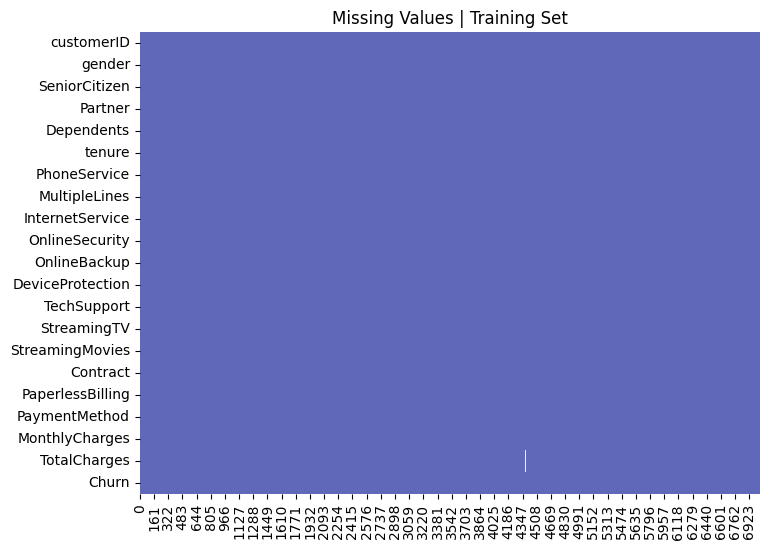

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
train_missing_values = df.isna()

def plot_missing(data, set_type='Training'):
    plt.figure(figsize=(8, 6))
    sns.heatmap(data.T, cmap=['#5F68B9', '#EAECFE'], cbar=False, yticklabels=True)
    plt.title(f'Missing Values | {set_type} Set')
    plt.show()

plot_missing(train_missing_values)


WE HAVE LOW NUMBER OF MISSING VALUES WE WILL DROP THE COLUMNS

In [ ]:
def drop_missing_rows(df):
    if df.isnull().any().any():
        print("Missing values found in the dataframe.")
        df_original=df
        df = df.dropna(axis=0)
        dropped_rows = len(df_original) - len(df)
        print(f"Dropped {dropped_rows} rows.")
    else:
        print("No missing values found in the dataframe.")

    return df
df=drop_missing_rows(df)

Missing values found in the dataframe.
Dropped 11 rows.


CHECKING FOR DUPLICATE ROWS

In [ ]:
def count_duplicate_rows(df):
    duplicate_rows = df[df.duplicated()]

    if not duplicate_rows.empty:
        print("Duplicate rows found in the dataframe.")
        count = len(duplicate_rows)
        print(f"Count of duplicate rows: {count}.")
    else:
        print("No duplicate rows found in the dataframe.")

    return df

df = count_duplicate_rows(df)

No duplicate rows found in the dataframe.


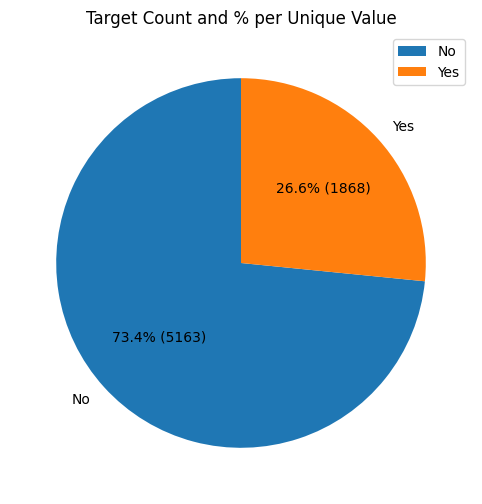

In [ ]:
# Target count and percentage per unique value
outcome_counts = df['Churn'].value_counts()
outcome_percentages = df['Churn'].value_counts(normalize=True) * 100

# Plotting
plt.figure(figsize=(8, 6))
plt.pie(outcome_counts, labels=outcome_counts.index, autopct=lambda p: f'{p:.1f}% ({int(p*len(df)/100)})', startangle=90)
plt.title('Target Count and % per Unique Value')
plt.legend(outcome_counts.index, loc="best")
plt.show()

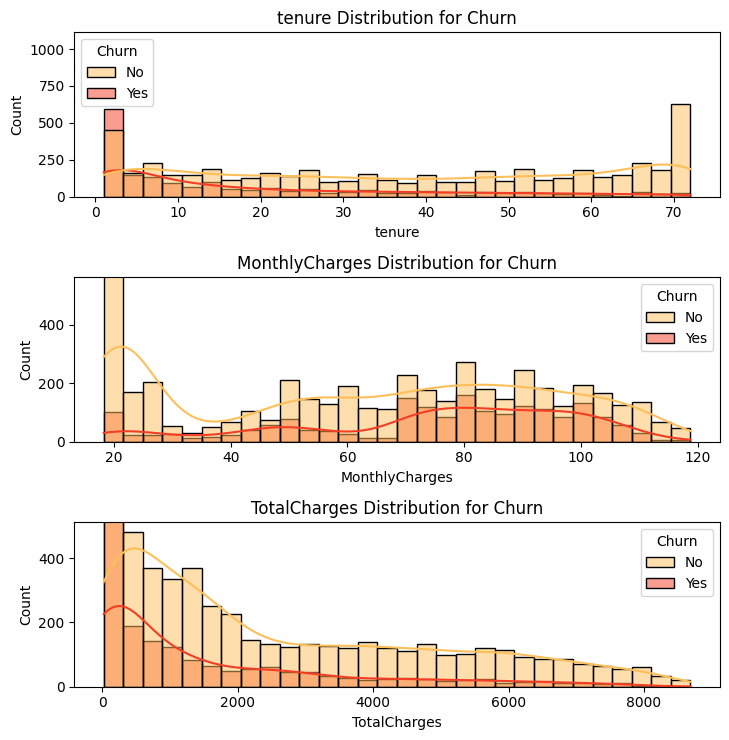

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, len(num_cols) * 2.5))

for idx, column in enumerate(num_cols):
    # Plotting for outcome
    plt.subplot(len(num_cols), 2, idx*2+1)
    sns.histplot(x=column, hue="Churn", data=df, bins=30, kde=True, palette='YlOrRd')
    plt.title(f"{column} Distribution for Churn")
    plt.ylim(0, df[column].value_counts().max() + 500)

plt.tight_layout()
plt.show()

Distribution Categorical Features

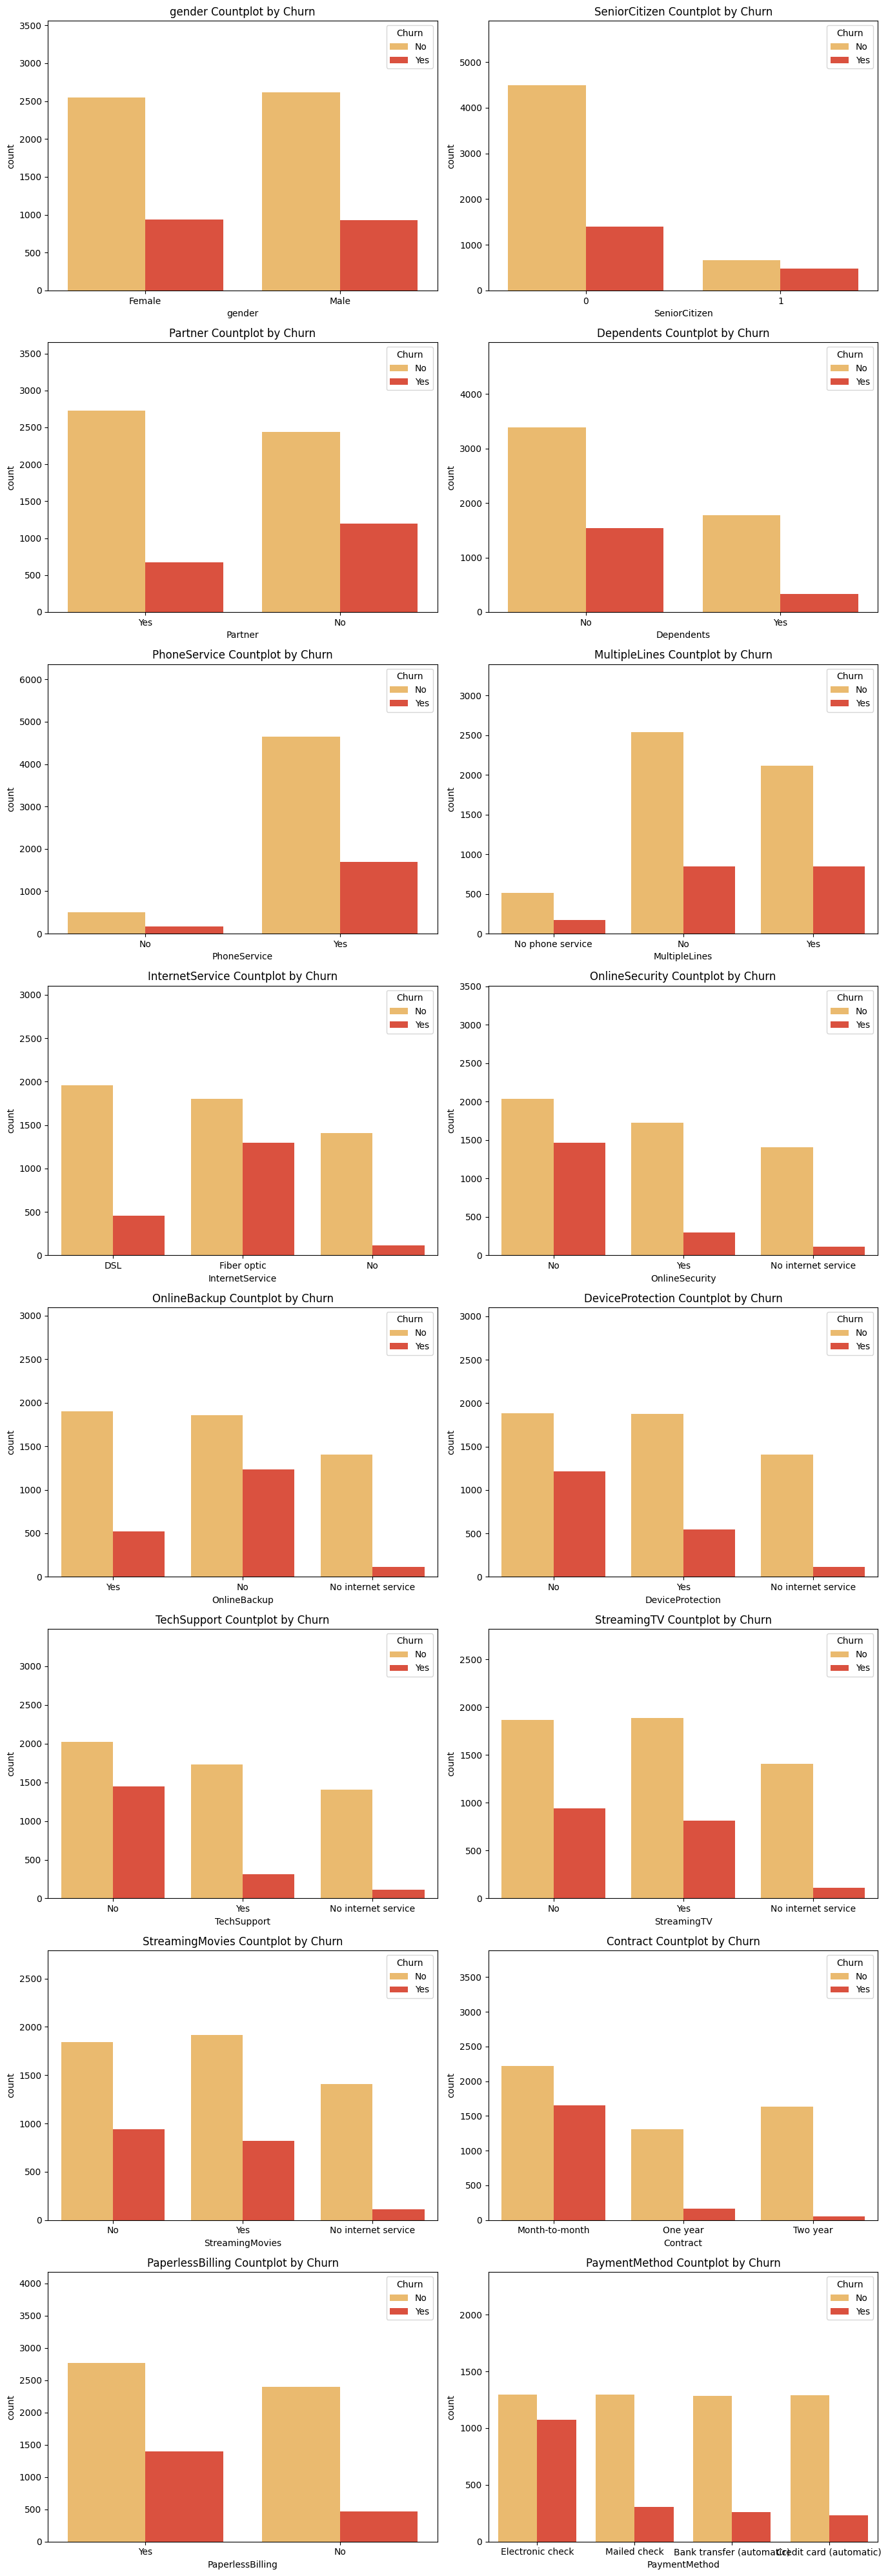

In [ ]:
plt.figure(figsize=(14, len(cat_vars)*2.5))

for idx, column in enumerate(cat_vars):
    plt.subplot(len(cat_vars)//2 + len(cat_vars) % 2, 2, idx+1)
    sns.countplot(x=column, hue="Churn", data=df, palette='YlOrRd')
    plt.title(f"{column} Countplot by Churn")
    plt.ylim(0, df[column].value_counts().max() + 10)

plt.tight_layout()
plt.show()

Correlation Numerical Columns

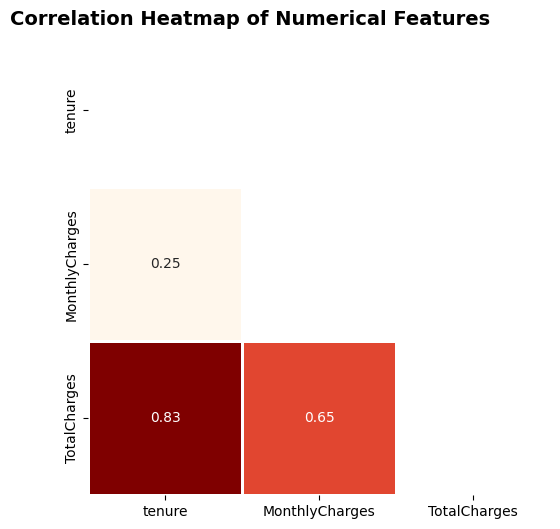

In [ ]:
corr_matrix = df[num_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(8, 6))
heatmap = sns.heatmap(corr_matrix, mask=mask, annot=True, square=True, cmap='OrRd', cbar=False, linewidths=1)
title = heatmap.set_title("Correlation Heatmap of Numerical Features", weight='bold', size=14)
title.set_position([0.35, 1.05])
plt.show()

One Hot Encoding

In [ ]:
df['Churn'] = df['Churn'].map({'No':0, 'Yes':1})

In [ ]:
def encode_and_bind(original_dataframe, feature_to_encode):
    dummies = pd.get_dummies(original_dataframe[[feature_to_encode]], drop_first=True)
    res = pd.concat([original_dataframe, dummies], axis=1)
    res = res.drop([feature_to_encode], axis=1)
    return res

In [ ]:
for feature in cat_vars:
    df = encode_and_bind(df, feature)

df.head()

,customerID,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,7590-VHVEG,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,5575-GNVDE,34,56.95,"1,889.50",0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,3668-QPYBK,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,7795-CFOCW,45,42.30,"1,840.75",0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,9237-HQITU,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


Feature Selection

<ipython-input-26-2a388367b66c>:3: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.corr()['Churn'].sort_values(ascending = False).plot(kind='bar')


<Axes: >

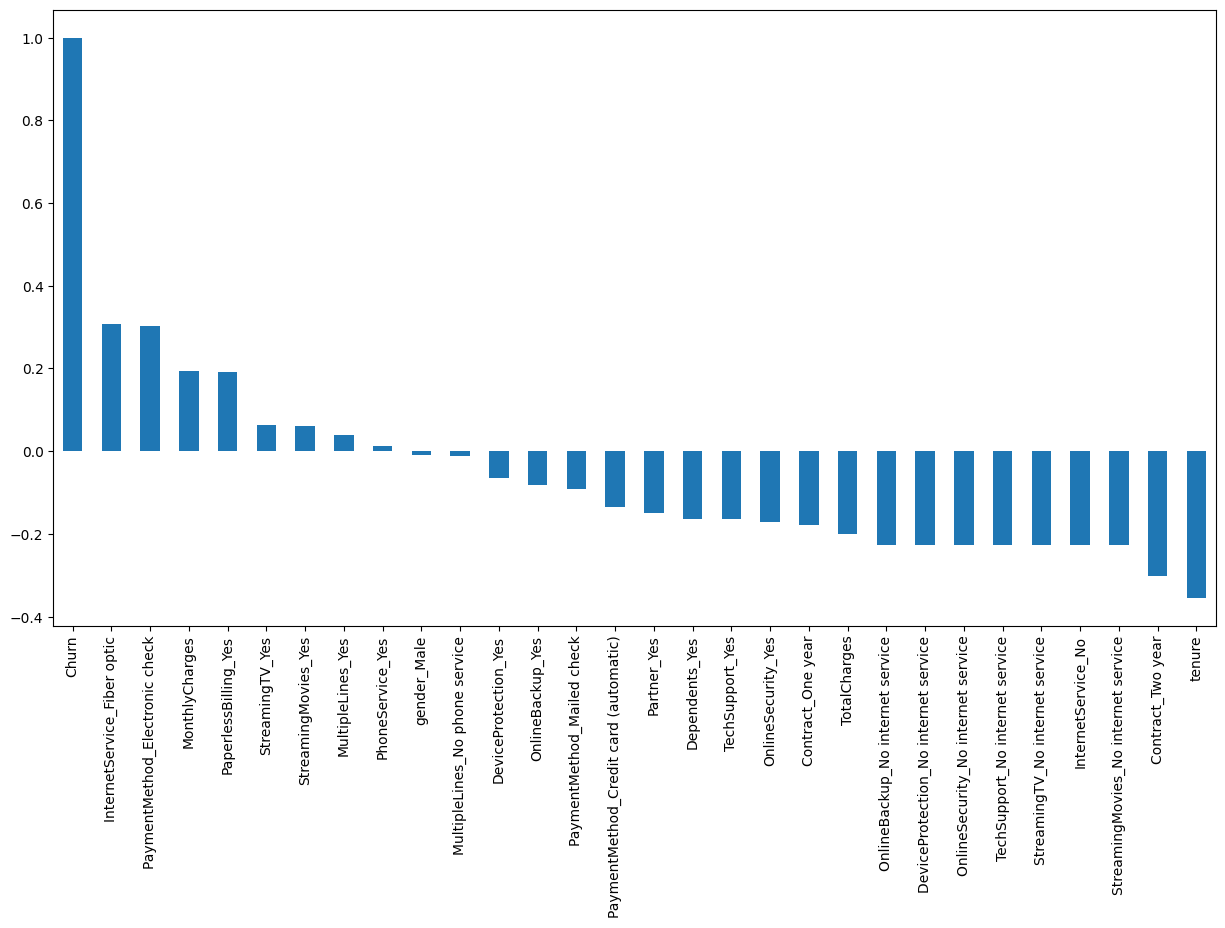

In [ ]:
#Get Correlation of "Churn" with other variables:
plt.figure(figsize=(15,8))
df.corr()['Churn'].sort_values(ascending = False).plot(kind='bar')

Now we are going to select the top features for the model (because we have done One-Hot-Encoding and there are to many variables at the moment). There are different ways to do this such as Manually selecting by the correlation (example ternure, contract 2 years, internet service......

In [ ]:
df.drop('customerID', axis=1, inplace=True)

In [ ]:
x = df.drop('Churn', axis=1).values
y = df['Churn']

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state=1234)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(random_state=1234)
rf_clf.fit(x_train, y_train)

RandomForestClassifier(random_state=1234)

<ipython-input-35-d853046df4cb>:12: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(best_vars)


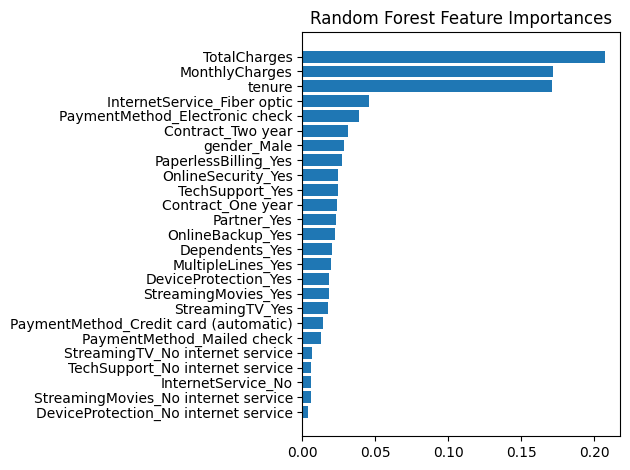

In [ ]:
rf_clf.feature_importances_
features_to_plot = 25

importances = rf_clf.feature_importances_
indices = np.argsort(importances)
feature_names = list(df.drop('Churn', axis=1).columns)
best_vars = np.array(feature_names)[indices][-features_to_plot:]
values = importances[indices][-features_to_plot:]
y_ticks = np.arange(0, features_to_plot)
fig, ax = plt.subplots()
ax.barh(y_ticks, values)
ax.set_yticklabels(best_vars)
ax.set_yticks(y_ticks)
ax.set_title("Random Forest Feature Importances")
fig.tight_layout()
plt.show()

WE SELECT 10 BEST FEATURES


In [ ]:
best_vars = best_vars[-10:]
best_vars

array(['TechSupport_Yes', 'OnlineSecurity_Yes', 'PaperlessBilling_Yes',
       'gender_Male', 'Contract_Two year',
       'PaymentMethod_Electronic check', 'InternetService_Fiber optic',
       'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='<U37')

**Data Exploration and Summary:**

Loaded the dataset using Pandas.
Displayed the first few rows of the dataset.
Created a function summary() to provide an overview of the dataset, including data types, missing values, duplicated rows, unique values, and descriptive statistics for numerical features.

**Data Cleaning:**

Converted numeric columns to the appropriate data type using the toNum function.
Checked for missing values and visualized them using a heatmap.
Dropped missing rows using the drop_missing_rows function.
Checked for and handled duplicate rows using the count_duplicate_rows function.

**Target Variable Analysis:**

Checked the distribution of the target variable 'Churn' and visualized it using a pie chart.

**Correlation Analysis:**

Computed and visualized the correlation matrix of numerical features using a heatmap.

**Feature Engineering:**

Encoded categorical variables using one-hot encoding.
Machine Learning Model (Random Forest):

We have used a Random Forest classifier (rf_clf)
Extracted feature importances from the trained Random Forest model and visualized the top features.